<center> <p style="text-align:center;font-family:arial"> <b>Universidade Federal de Alagoas</b></p>


<p style="text-align:center;font-family:arial"> <b>Instituto de Computação - PPGI - IC</b></p>


<p style="text-align:center;font-family:arial"> <b>Processamento de Linguagem Natural</b></p></center>


<p style="font-family:arial">Professor: Thales Vieira</p>

<p style="font-family:arial">Aluno: Edvonaldo Horácio dos Santos ( matrícula 2022104210)</p>

<center><p style="text-align:center;font-family:arial"> <b>2ª Lista de Exercícios</>

## Escolha dos textos

In [ ]:
# Import libs
import os
import re
import nltk
import random
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from nltk.tokenize import RegexpTokenizer
from google.colab import drive

In [ ]:
# Mount drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
path = '/content/drive/MyDrive/dataset_pln_2022.2/corpus_bcc.csv'

df_corpus = pd.read_csv(path, sep=';')
print("Shape dataframe: ", df_corpus.shape)
df_corpus.describe()

Shape dataframe:  (2225, 4)


,Unnamed: 0,id
count,2225.000000,2225.000000
mean,225.321798,226.321798
std,134.218688,134.218688
min,0.000000,1.000000
25%,111.000000,112.000000
50%,222.000000,223.000000
75%,333.000000,334.000000
max,510.000000,511.000000


In [ ]:
df_corpus.columns

Index(['Unnamed: 0', 'id', 'content', 'label'], dtype='object')

In [ ]:
df_corpus.groupby(by=['label']).count()

,Unnamed: 0,id,content
label,,,
business,510,510,510
entertainment,386,386,386
politics,417,417,417
sport,511,511,511
tech,401,401,401


In [ ]:
df_corpus['label'][1823]

'sport'

In [ ]:
# Choose text in base; 2 each label
random.seed(45256)
text_b11 = random.randint(0,509)
text_b12 = random.randint(0,509)

text_e11 = random.randint(510,895)
text_e12 = random.randint(510,895)

text_p11 = random.randint(896, 1312)
text_p12 = random.randint(896, 1312)

text_s11 = random.randint(1313, 1823)
text_s12 = random.randint(1313, 1823)

text_t11 = random.randint(1824, 2224)
text_t12 = random.randint(1824, 2224)

texts_idx = [text_b11, text_b12, text_e11, text_e12, text_p11, text_p12, 
         text_s11, text_s12, text_t11, text_t12]

print(texts_idx)

[261, 287, 726, 512, 1101, 992, 1328, 1789, 1860, 1873]


In [ ]:
df_select10 = pd.DataFrame(data=df_corpus.iloc[texts_idx], columns=df_corpus.columns)

df_select10

,Unnamed: 0,id,content,label
261,261,262,Asian quake hits European shares\n\nShares in ...,business
287,287,288,GE sees 'excellent' world economy\n\nUS behemo...,business
726,216,217,Baywatch dubbed 'worst TV import'\n\nSurf show...,entertainment
512,2,3,Musical treatment for Capra film\n\nThe classi...,entertainment
1101,205,206,Blair's hope for Blunkett return\n\nThe events...,politics
992,96,97,UK plan to deport terror suspects\n\nDeals are...,politics
1328,15,16,Verdict delay for Greek sprinters\n\nGreek ath...,sport
1789,476,477,Moya suffers shock loss\n\nFifth seed Carlos M...,sport
1860,36,37,US woman sues over cartridges\n\nA US woman is...,tech
1873,49,50,Cheaper chip for mobiles\n\nA mobile phone chi...,tech


In [ ]:
df_select10 = df_select10.reset_index()

df_select10.head(5)

,index,Unnamed: 0,id,content,label
0,261,261,262,Asian quake hits European shares\n\nShares in ...,business
1,287,287,288,GE sees 'excellent' world economy\n\nUS behemo...,business
2,726,216,217,Baywatch dubbed 'worst TV import'\n\nSurf show...,entertainment
3,512,2,3,Musical treatment for Capra film\n\nThe classi...,entertainment
4,1101,205,206,Blair's hope for Blunkett return\n\nThe events...,politics


In [ ]:
df_select10 = df_select10.drop(columns=['index'], axis=1)
df_select10.head(5)

,Unnamed: 0,id,content,label
0,261,262,Asian quake hits European shares\n\nShares in ...,business
1,287,288,GE sees 'excellent' world economy\n\nUS behemo...,business
2,216,217,Baywatch dubbed 'worst TV import'\n\nSurf show...,entertainment
3,2,3,Musical treatment for Capra film\n\nThe classi...,entertainment
4,205,206,Blair's hope for Blunkett return\n\nThe events...,politics


## Pré-processamento

In [ ]:
def remove_punctuation(text):
  return  re.sub('[%s]' % re.escape(string.punctuation), ' ', text)

df_select10 = df_select10.replace(to_replace=r'\w*\d\w*', value='', regex=True) # Retirando numeros

In [ ]:
for i in range(df_select10['content'].shape[0]):  #Todas  lowercase
  df_select10['content'][i] = df_select10['content'][i].lower()

df_select10['content'] = df_select10['content'].apply(remove_punctuation) # Removendo pontuação

df_select10.head()

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


,Unnamed: 0,id,content,label
0,261,262,asian quake hits european shares\n\nshares in ...,business
1,287,288,ge sees excellent world economy\n\nus behemo...,business
2,216,217,baywatch dubbed worst tv import \n\nsurf show...,entertainment
3,2,3,musical treatment for capra film\n\nthe classi...,entertainment
4,205,206,blair s hope for blunkett return\n\nthe events...,politics


# Questão 1 

## (a) Count Vectorizer

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(stop_words='english')
x_token_text = cv.fit_transform(df_select10.content)
pd_vectorize = pd.DataFrame(x_token_text.toarray(), columns=cv.get_feature_names())
print(pd_vectorize)

   ability  accident  according  account  accused  acquitted  actually  added  \
0        0         0          0        1        0          0         0      0   
1        0         0          0        0        0          0         0      0   
2        0         0          1        0        0          0         0      0   
3        0         0          0        0        0          0         0      0   
4        1         0          0        0        0          0         0      0   
5        1         0          0        0        2          0         2      1   
6        0         1          0        0        0          1         0      0   
7        0         0          0        0        0          0         0      0   
8        0         0          0        0        0          0         0      0   
9        0         0          0        1        0          0         0      0   

   adjustments  advise  ...  worried  worries  worst  worth  wrong  wrote  \
0            1       0  ...    

/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


In [ ]:
#Calculando para todos os documentos a similaridade por cosseno.
from itertools import combinations
from sklearn.metrics.pairwise import cosine_similarity

pairs = list(combinations(range(df_select10.shape[0]),2)) #Pegando os pares de index
combos = [(df_select10['content'][a_index], df_select10['content'][b_index]) for (a_index, b_index) in pairs] # Quais os contets


results = [cosine_similarity(x_token_text[a_index], x_token_text[b_index]) for (a_index, b_index) in pairs] #Fazendo cosseno
sorted(zip(results, combos), reverse=True) #Comparando o cosseno com o texto.

[(array([[0.32905804]]),
  ('blair s hope for blunkett return\n\nthe events leading to david blunkett s resignation must not  swept under the carpet   the tories have warned \n\non wednesday tony blair said he hoped the former home secretary would serve again in government in the future  mr blunkett quit in december after a probe linked him to the visa application of his ex lover s nanny  mr blair said he left  without a stain on his character  but tory dominic grieve branded the way mr blunkett s office operated as  scandalous   mr blair told bbc radio  s today programme   i know david very well and i believe him to be a man of real integrity and real ability and i was very sad for him as to what happened  \n\nhe said mr blunkett still had an immense amount to offer the country but he was not making any  guarantees or definitive statements  about future jobs  but shadow attorney general mr grieve said   while i don t rule out the possibility that mr blunkett may return as a minister  

Trechos mais parecidos

1 - blair s hope for blunkett return\n\nthe events leading to david blunkett s resignation must not  swept under the carpet   the tories have warned 

2 - musical treatment for capra film\n\nthe classic film it s a wonderful life is to be turned into a musical by the producer of the controversial hit show jerry springer   the opera

3 - asian quake hits european shares\n\nshares in europe s leading reinsurers and travel firms have fallen as the scale of the damage wrought by tsunamis across south asia has become apparent 

## (b) TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
cv_tfidf = TfidfVectorizer(stop_words="english")
x_token_text_tfidf = cv_tfidf.fit_transform(df_select10.content)
pd_vectorize_tfidf = pd.DataFrame(x_token_text_tfidf.toarray(), columns=cv.get_feature_names())
print(pd_vectorize_tfidf)

    ability  accident  according   account   accused  acquitted  actually  \
0  0.000000  0.000000   0.000000  0.036990  0.000000   0.000000  0.000000   
1  0.000000  0.000000   0.000000  0.000000  0.000000   0.000000  0.000000   
2  0.000000  0.000000   0.081987  0.000000  0.000000   0.000000  0.000000   
3  0.000000  0.000000   0.000000  0.000000  0.000000   0.000000  0.000000   
4  0.059492  0.000000   0.000000  0.000000  0.000000   0.000000  0.000000   
5  0.042223  0.000000   0.000000  0.000000  0.099338   0.000000  0.099338   
6  0.000000  0.068567   0.000000  0.000000  0.000000   0.068567  0.000000   
7  0.000000  0.000000   0.000000  0.000000  0.000000   0.000000  0.000000   
8  0.000000  0.000000   0.000000  0.000000  0.000000   0.000000  0.000000   
9  0.000000  0.000000   0.000000  0.040582  0.000000   0.000000  0.000000   

      added  adjustments    advise  ...   worried   worries     worst  \
0  0.000000     0.043513  0.000000  ...  0.043513  0.043513  0.073980   
1  0.0

/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


In [ ]:
results_tfidf = [cosine_similarity(x_token_text_tfidf[a_index], x_token_text_tfidf[b_index]) for (a_index, b_index) in pairs]
sorted(zip(results_tfidf, combos), reverse=True)

[(array([[0.19248008]]),
  ('blair s hope for blunkett return\n\nthe events leading to david blunkett s resignation must not  swept under the carpet   the tories have warned \n\non wednesday tony blair said he hoped the former home secretary would serve again in government in the future  mr blunkett quit in december after a probe linked him to the visa application of his ex lover s nanny  mr blair said he left  without a stain on his character  but tory dominic grieve branded the way mr blunkett s office operated as  scandalous   mr blair told bbc radio  s today programme   i know david very well and i believe him to be a man of real integrity and real ability and i was very sad for him as to what happened  \n\nhe said mr blunkett still had an immense amount to offer the country but he was not making any  guarantees or definitive statements  about future jobs  but shadow attorney general mr grieve said   while i don t rule out the possibility that mr blunkett may return as a minister  

Trechos mais parecidos

1 - blair s hope for blunkett return\n\nthe events leading to david blunkett s resignation must not  swept under the carpet   the tories have warned

2 - asian quake hits european shares\n\nshares in europe s leading reinsurers and travel firms have fallen as the scale of the damage wrought by tsunamis across south asia has become apparent 

3 - us woman sues over cartridges\n\na us woman is suing hewlett packard  hp   saying its printer ink cartridges are secretly programmed to expire on a certain date

# Questão 2

## (a) Rótulo dos documentos

Primeiro vamos verificar a quantidade de textos de cada label.

In [ ]:
df_corpus.groupby(by=['label']).count()

,Unnamed: 0,id,content
label,,,
business,510,510,510
entertainment,386,386,386
politics,417,417,417
sport,511,511,511
tech,401,401,401


Notemos que há quantidades distintas de cada um dos 5 tipos. Tomando a quantidade de label e comparando 2 a 2, vemos que aquelas que possuem uma quantidade mais próxima são BUSINESS e SPORT com 510 e 511, respectivamente.
 
O balanceamento é importante para evitar algum tipo de viés da base no treinamento dos modelos.

In [ ]:
df_business = df_corpus.loc[df_corpus['label'] == 'business']
df_sport = df_corpus.loc[df_corpus['label'] == 'sport']

frames = [df_business, df_sport]

df_binary = pd.concat(frames)

df_binary.groupby(by=['label']).count()

,Unnamed: 0,id,content
label,,,
business,510,510,510
sport,511,511,511


### Pré-processamento

In [ ]:
# Removendo palavras que contém números
# Removendo as palavras que contém numeros
df_binary['content'] = df_binary['content'].replace(to_replace=r'\w*\d\w*', value='', regex=True)
df_binary.head(5)

,Unnamed: 0,id,content,label
0,0,1,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,1,2,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,2,3,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,3,4,High fuel prices hit BA's profits\n\nBritish A...,business
4,4,5,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [ ]:
df_binary['content'] = df_binary['content'].apply(remove_punctuation)# Removendo pontuação

df_binary['content'] = df_binary.content.str.lower()# Deixando tudo minúsculo
df_binary.content

0       ad sales boost time warner profit\n\nquarterly...
1       dollar gains on greenspan speech\n\nthe dollar...
2       yukos unit buyer faces loan claim\n\nthe owner...
3       high fuel prices hit ba s profits\n\nbritish a...
4       pernod takeover talk lifts domecq\n\nshares in...
                              ...                        
1819    big guns ease through in san jose\n\ntop seede...
1820    almagro continues spanish surge\n\nunseeded ni...
1821    melzer shocks agassi in san jose\n\nsecond see...
1822    mirza makes indian tennis history\n\nteenager ...
1823    roddick to face saulnier in final\n\nandy rodd...
Name: content, Length: 1021, dtype: object

In [ ]:
X = df_binary.content
y = df_binary.label

In [ ]:
print("Shape X: ", X.shape)
print("Shape y: ", y.shape)

Shape X:  (1021,)
Shape y:  (1021,)


### Separando em treino e teste

In [ ]:
from sklearn.model_selection import train_test_split as tts

X_train, X_test, y_train, y_test = tts(X, y, test_size=0.3, random_state=42)

print("X train: ", X_train.shape)
print("Y train: ", y_train.shape)
print("X test: ", X_test.shape)
print("Y test: ", y_test.shape)

X train:  (714,)
Y train:  (714,)
X test:  (307,)
Y test:  (307,)


## (b) Representações vetoriais (etapa de transformação no KDD)

### Count Vectorizer

In [ ]:
# Step 3 - Enconde the input using One-Hot Encode
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(stop_words='english')

X_train_cv = cv.fit_transform(X_train)
X_test_cv = cv.transform(X_test)
print("X_train_cv: ", X_train_cv.toarray().shape)
print("X_test_cv: ", X_test_cv.toarray().shape)

X_train_cv:  (714, 13673)
X_test_cv:  (307, 13673)


### TF-IDF

In [ ]:
# Step 3 - Enconde the input using One-Hot Encode
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words='english')

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("x_train_tfidf: ", X_train_tfidf.toarray().shape)
print("X_test_tfidf: ", X_test_tfidf.toarray().shape)

x_train_tfidf:  (714, 13673)
X_test_tfidf:  (307, 13673)


## (c) Classificador usando Regressão Logística

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_cv = LogisticRegression()
lr_tfidf = LogisticRegression()

lr_cv.fit(X_train_cv, y_train)
lr_tfidf.fit(X_train_tfidf, y_train)

y_pred_cv_lr = lr_cv.predict(X_test_cv)
y_pred_tfidf_lr = lr_tfidf.predict(X_test_tfidf)

#print("y_pred_cv: ", y_pred_cv)
#print("y_true: ", y_test)
#print("y_pred_tfidf: ", y_pred_tfidf)

### Matriz confusão Count Vectorizer

In [ ]:
# Setp 5 - Evaluate Logistic Regression
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_lr_cv = confusion_matrix(y_test, y_pred_cv_lr)

In [ ]:
sport_true = int(0)
sport_pred_cv_lr = int(0)
business_true = int(0)
business_pred_cv_lr = int(0)

for idx, cont in enumerate(y_test):
  if cont == "sport":
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_cv_lr):
  if cont2 == "sport":
    sport_pred_cv_lr = sport_pred_cv_lr + 1
  else:
    business_pred_cv_lr = business_pred_cv_lr + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred: ", sport_pred_cv_lr)
print("Business pred ", business_pred_cv_lr)
print("Confusion matrix: Logistic Regression")
print(cm_lr_cv)

Sport true:  150
Business true:  157
Sport pred:  152
Business pred  155
Confusion matrix: Logistic Regression
[[155   2]
 [  0 150]]


In [ ]:
group_names_lr_cv = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_lr_cv = ["{0:0.0f}".format(value) for value in cm_lr_cv.flatten()]

group_per_lr_cv = ["{0:.2%}".format(value) for value in cm_lr_cv.flatten()/np.sum(cm_lr_cv)]

labels_lr_cv = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_lr_cv, group_counts_lr_cv, group_per_lr_cv)]

labels_lr_cv = np.asarray(labels_lr_cv).reshape(2, 2)

Text(33.0, 0.5, 'TRUE LABELS')

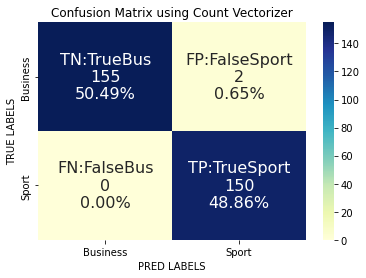

In [ ]:
# Ref confusion matrix: https://medium.com/@dtuk81/confusion-matrix-visualization-fc31e3f30fea

#sns.heatmap(cm_lr_cv, xticklabels=['Business','Sport'], \
#            yticklabels=['Business', 'Sport'],\
#            annot=True, fmt='d', annot_kws={'fontsize':20}, cmap="YlGnBu")
ax = plt.subplot()
sns.heatmap(cm_lr_cv, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_lr_cv, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax)
ax.set_title('Confusion Matrix using Count Vectorizer')
ax.set_xlabel('PRED LABELS');ax.set_ylabel('TRUE LABELS')

### Métricas usando Count Vectorizer

In [ ]:
# Função para calcular métricas
def calc_metrics(tp, tn, fp, fn):
  accuracy = (tp + tn)/(tp + fp + tn + fn)
  precision = (tp)/(tp + fp)
  recall = (tp) / (tp + fn)
  f1_score = 2 * (precision * recall) / (precision + recall)

  return accuracy, precision, recall, f1_score

In [ ]:
tp_lr_cv = 150
tn_lr_cv = 155
fp_lr_cv = 2
fn_lr_cv = 0

acc_cv_lr, prec_cv_lr, recall_cv_lr, f1_score_cv_lr = calc_metrics(tp_lr_cv, tn_lr_cv, fp_lr_cv, fn_lr_cv)

print("/-- Métricas: Regressão Logística usando Count Vectorizer --/")
print("Acurácia: ", round(lr_cv.score(X_test_cv, y_pred_cv_lr)))
print("Precisão: ", round(prec_cv_lr, 4))# tp / (tp + fp)
print("Recall: ", round(recall_cv_lr, 4))
print("F1-score: ", round(f1_score_cv_lr, 4))

/-- Métricas: Regressão Logística usando Count Vectorizer --/
Acurácia:  1
Precisão:  0.9868
Recall:  1.0
F1-score:  0.9934


### Matriz confusão TF-IDF

In [ ]:
cm_lr_tfidf = confusion_matrix(y_test, y_pred_tfidf_lr)

sport_true = int(0)
sport_pred_tfidf_lr = int(0)
business_true = int(0)
business_pred_tfidf_lr = int(0)

for idx, cont in enumerate(y_test):
  if cont == "sport":
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_cv_lr):
  if cont2 == "sport":
    sport_pred_cv = sport_pred_tfidf_lr + 1
  else:
    business_pred_cv = business_pred_tfidf_lr + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred TF-IDF: ", sport_pred_tfidf_lr)
print("Business pred TF-IDF", business_pred_tfidf_lr)
print("Confusion matrix TF-IDF: Logistic Regression")
print(cm_lr_tfidf)

Sport true:  150
Business true:  157
Sport pred TF-IDF:  0
Business pred TF-IDF 0
Confusion matrix TF-IDF: Logistic Regression
[[157   0]
 [  0 150]]


In [ ]:
group_names_lr_tfidf = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_lr_tfidf = ["{0:0.0f}".format(value) for value in cm_lr_tfidf.flatten()]

group_per_lr_tfidf = ["{0:.2%}".format(value) for value in cm_lr_tfidf.flatten()/np.sum(cm_lr_tfidf)]

labels_lr_tfidf = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_lr_tfidf, group_counts_lr_tfidf, group_per_lr_tfidf)]

labels_lr_tfidf = np.asarray(labels_lr_tfidf).reshape(2, 2)

Text(33.0, 0.5, 'TRUE LABELS')

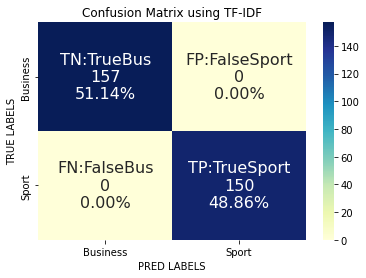

In [ ]:
ax = plt.subplot()
sns.heatmap(cm_lr_tfidf, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_lr_tfidf, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax)
ax.set_title('Confusion Matrix using TF-IDF')
ax.set_xlabel('PRED LABELS');ax.set_ylabel('TRUE LABELS')

### Métricas usando TF-IDF

In [ ]:
tp_lr_tfidf = 150
tn_lr_tfidf = 157
fp_lr_tfidf = 0
fn_lr_tfidf = 0

acc_tfidf_lr, prec_tfidf_lr, recall_tfidf_lr, f1_score_tfidf_lr = calc_metrics(tp_lr_tfidf, tn_lr_tfidf, fp_lr_tfidf, fn_lr_tfidf)

print("/-- Métricas: Regressão Logística usando TF-IDF --/")
print("Acurácia: ", round(lr_tfidf.score(X_test_cv, y_pred_tfidf_lr)))
print("Precisão: ", round(prec_tfidf_lr, 4))
print("Recall: ", round(recall_tfidf_lr, 4))
print("F1-score: ", round(f1_score_tfidf_lr, 4))

/-- Métricas: Regressão Logística usando TF-IDF --/
Acurácia:  1
Precisão:  1.0
Recall:  1.0
F1-score:  1.0


## (d) Classificador usando Naive-Bayes

In [ ]:
X_train_cv_dense = X_train_cv.toarray()
X_test_cv_dense = X_test_cv.toarray()
X_train_tfidf_dense = X_train_tfidf.toarray()
X_test_tfidf_dense = X_test_tfidf.toarray()

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb_cv = GaussianNB()
nb_tfidf = GaussianNB()

nb_cv.fit(X_train_cv_dense, y_train)
nb_tfidf.fit(X_train_tfidf_dense, y_train)

y_pred_cv_nb = nb_cv.predict(X_test_cv_dense)
y_pred_tfidf_nb = nb_tfidf.predict(X_test_tfidf_dense)

### Matriz confusão usando Count Vectorizer

In [ ]:
cm_nb_cv = confusion_matrix(y_test, y_pred_cv_nb)

sport_true = int(0)
sport_pred_cv_nb = int(0)
business_true = int(0)
business_pred_cv_nb = int(0)

for idx, cont in enumerate(y_test):
  if cont == "sport":
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_cv_nb):
  if cont2 == "sport":
    sport_pred_cv_nb = sport_pred_cv_nb + 1
  else:
    business_pred_cv_nb = business_pred_cv_nb + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred: ", sport_pred_cv_nb)
print("Business pred ", business_pred_cv_nb)
print("Confusion matrix: Logistic Regression")
print(cm_nb_cv)

Sport true:  150
Business true:  157
Sport pred:  151
Business pred  156
Confusion matrix: Logistic Regression
[[156   1]
 [  0 150]]


In [ ]:
group_names_nb_cv = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_nb_cv = ["{0:0.0f}".format(value) for value in cm_nb_cv.flatten()]

group_per_nb_cv = ["{0:.2%}".format(value) for value in cm_nb_cv.flatten()/np.sum(cm_nb_cv)]

labels_nb_cv = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_lr_cv, group_counts_nb_cv, group_per_nb_cv)]

labels_nb_cv = np.asarray(labels_nb_cv).reshape(2, 2)

Text(17.2, 0.5, 'TRUE LABELS')

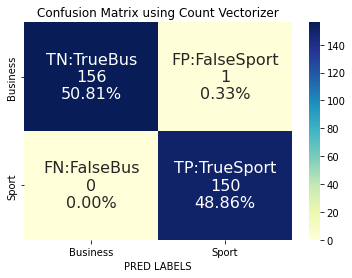

In [ ]:
ax_nb_cv = plt.subplot()
sns.heatmap(cm_nb_cv, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_nb_cv, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax_nb_cv)
ax_nb_cv.set_title('Confusion Matrix using Count Vectorizer')
ax_nb_cv.set_xlabel('PRED LABELS');
ax.set_ylabel('TRUE LABELS')

### Métricas usando Count Vectorizer

In [ ]:
tp_nb_cv = 150
tn_nb_cv = 156
fp_nb_cv = 1
fn_nb_cv = 0

acc_cv_nb, prec_cv_nb, recall_cv_nb, f1_score_cv_nb = calc_metrics(tp_nb_cv, tn_nb_cv, fp_nb_cv, fn_nb_cv)

print("/-- Métricas: Naive-Bayes usando Count Vectorizer --/")
print("Acurácia: ", round(nb_cv.score(X_test_cv_dense, y_pred_cv_nb)))
print("Precisão: ", round(prec_cv_nb, 4))# tp / (tp + fp)
print("Recall: ", round(recall_cv_nb, 4))
print("F1-score: ", round(f1_score_cv_nb, 4))

/-- Métricas: Naive-Bayes usando Count Vectorizer --/
Acurácia:  1
Precisão:  0.9934
Recall:  1.0
F1-score:  0.9967


### Matriz confusão usando TF-IDF

In [ ]:
cm_nb_tfidf = confusion_matrix(y_test, y_pred_tfidf_nb)

sport_true = int(0)
sport_pred_tfidf_nb = int(0)
business_true = int(0)
business_pred_tfidf_nb = int(0)

for idx, cont in enumerate(y_test):
  if cont == "sport":
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_tfidf_nb):
  if cont2 == "sport":
    sport_pred_tfidf_nb = sport_pred_tfidf_nb + 1
  else:
    business_pred_tfidf_nb = business_pred_tfidf_nb + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred: ", sport_pred_tfidf_nb)
print("Business pred ", business_pred_tfidf_nb)
print("Confusion matrix: Naive-Bayes")
print(cm_nb_tfidf)

Sport true:  150
Business true:  157
Sport pred:  153
Business pred  154
Confusion matrix: Naive-Bayes
[[154   3]
 [  0 150]]


In [ ]:
group_names_nb_tfidf = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_nb_tfidf = ["{0:0.0f}".format(value) for value in cm_nb_tfidf.flatten()]

group_per_nb_tfidf = ["{0:.2%}".format(value) for value in cm_nb_tfidf.flatten()/np.sum(cm_nb_tfidf)]

labels_nb_tfidf = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_nb_tfidf, group_counts_nb_tfidf, group_per_nb_tfidf)]

labels_nb_tfidf = np.asarray(labels_nb_tfidf).reshape(2, 2)

Text(33.0, 0.5, 'TRUE LABELS')

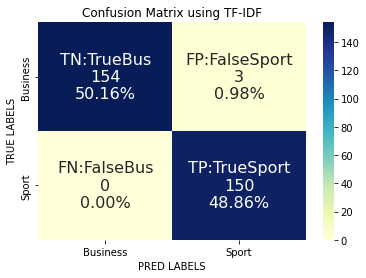

In [ ]:
ax_nb_tfidf = plt.subplot()
sns.heatmap(cm_nb_tfidf, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_nb_tfidf, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax_nb_tfidf)
ax_nb_tfidf.set_title('Confusion Matrix using TF-IDF')
ax_nb_tfidf.set_xlabel('PRED LABELS');
ax_nb_tfidf.set_ylabel('TRUE LABELS')

### Métricas usando TF-IDF

In [ ]:
tp_nb_tfidf = 150
tn_nb_tfidf = 154
fp_nb_tfidf = 3
fn_nb_tfidf = 0

acc_tfidf_nb, prec_tfidf_nb, recall_tfidf_nb, f1_score_tfidf_nb = calc_metrics(tp_nb_tfidf, tn_nb_tfidf, fp_nb_tfidf, fn_nb_tfidf)

print("/-- Métricas: Naive-Bayes usando Count Vectorizer --/")
print("Acurácia: ", round(nb_tfidf.score(X_test_tfidf_dense, y_pred_tfidf_nb)))
print("Precisão: ", round(prec_tfidf_nb, 4))# tp / (tp + fp)
print("Recall: ", round(recall_tfidf_nb, 4))
print("F1-score: ", round(f1_score_tfidf_nb, 4))

/-- Métricas: Naive-Bayes usando Count Vectorizer --/
Acurácia:  1
Precisão:  0.9804
Recall:  1.0
F1-score:  0.9901


## (e) Classificador escolhido: SVM

In [ ]:
from sklearn.svm import SVC

svm_cv = SVC()
svm_tfidf = SVC()

svm_cv.fit(X_train_cv, y_train)
svm_tfidf.fit(X_train_tfidf, y_train)

y_pred_cv_svm = svm_cv.predict(X_test_cv)
y_pred_tfidf_svm = svm_tfidf.predict(X_test_tfidf)

### Matriz confusão usando Count Vectorizer

In [ ]:
cm_svm_cv = confusion_matrix(y_test, y_pred_cv_svm)

sport_true = int(0)
sport_pred_cv_svm = int(0)
business_true = int(0)
business_pred_cv_svm = int(0)

for idx, cont in enumerate(y_test):
  if cont == "sport":
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_cv_svm):
  if cont2 == "sport":
    sport_pred_cv_svm = sport_pred_cv_svm + 1
  else:
    business_pred_cv_svm = business_pred_cv_svm + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred: ", sport_pred_cv_svm)
print("Business pred ", business_pred_cv_svm)
print("Confusion matrix: Logistic Regression")
print(cm_svm_cv)

Sport true:  150
Business true:  157
Sport pred:  147
Business pred  160
Confusion matrix: Logistic Regression
[[156   1]
 [  4 146]]


In [ ]:
group_names_svm_cv = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_svm_cv = ["{0:0.0f}".format(value) for value in cm_svm_cv.flatten()]

group_per_svm_cv = ["{0:.2%}".format(value) for value in cm_svm_cv.flatten()/np.sum(cm_svm_cv)]

labels_svm_cv = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_svm_cv, group_counts_svm_cv, group_per_svm_cv)]

labels_svm_cv = np.asarray(labels_svm_cv).reshape(2, 2)

Text(33.0, 0.5, 'TRUE LABELS')

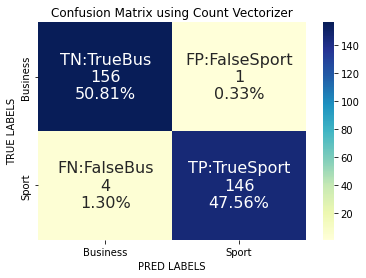

In [ ]:
ax_svm_cv = plt.subplot()
sns.heatmap(cm_svm_cv, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_svm_cv, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax_svm_cv)
ax_svm_cv.set_title('Confusion Matrix using Count Vectorizer')
ax_svm_cv.set_xlabel('PRED LABELS');
ax_svm_cv.set_ylabel('TRUE LABELS')

### Métricas usando Count Vectorizer

In [ ]:
tp_svm_cv = 146
tn_svm_cv = 156
fp_svm_cv = 1
fn_svm_cv = 4

acc_cv_svm, prec_cv_svm, recall_cv_svm, f1_score_cv_svm = calc_metrics(tp_svm_cv, tn_svm_cv, fp_svm_cv, fn_svm_cv)

print("/-- Métricas: Suport Vector Machine usando Count Vectorizer --/")
print("Acurácia: ", round(svm_cv.score(X_test_cv, y_pred_cv_svm)))
print("Precisão: ", round(prec_cv_svm, 4))# tp / (tp + fp)
print("Recall: ", round(recall_cv_svm, 4))
print("F1-score: ", round(f1_score_cv_svm, 4))

/-- Métricas: Suport Vector Machine usando Count Vectorizer --/
Acurácia:  1
Precisão:  0.9932
Recall:  0.9733
F1-score:  0.9832


### Matriz confusão usando TF-IDF

In [ ]:
cm_svm_tfidf = confusion_matrix(y_test, y_pred_tfidf_svm)

sport_true = int(0)
sport_pred_tfidf_svm = int(0)
business_true = int(0)
business_pred_tfidf_svm = int(0)

for idx, cont in enumerate(y_test):
  if cont == "sport":
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_tfidf_svm):
  if cont2 == "sport":
    sport_pred_tfidf_svm = sport_pred_tfidf_svm + 1
  else:
    business_pred_tfidf_svm = business_pred_tfidf_svm + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred: ", sport_pred_tfidf_svm)
print("Business pred ", business_pred_tfidf_svm)
print("Confusion matrix: SVM")
print(cm_svm_tfidf)

Sport true:  150
Business true:  157
Sport pred:  150
Business pred  157
Confusion matrix: SVM
[[157   0]
 [  0 150]]


In [ ]:
group_names_svm_tfidf = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_svm_tfidf = ["{0:0.0f}".format(value) for value in cm_svm_tfidf.flatten()]

group_per_svm_tfidf = ["{0:.2%}".format(value) for value in cm_svm_tfidf.flatten()/np.sum(cm_svm_tfidf)]

labels_svm_tfidf = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_svm_tfidf, group_counts_svm_tfidf, group_per_svm_tfidf)]

labels_svm_tfidf = np.asarray(labels_svm_tfidf).reshape(2, 2)

Text(33.0, 0.5, 'TRUE LABELS')

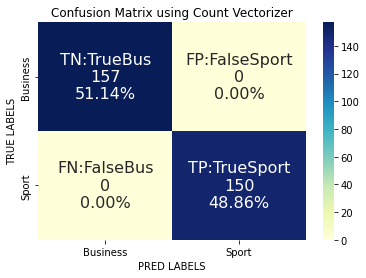

In [ ]:
ax_svm_tfidf = plt.subplot()
sns.heatmap(cm_svm_tfidf, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_svm_tfidf, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax_svm_tfidf)
ax_svm_tfidf.set_title('Confusion Matrix using Count Vectorizer')
ax_svm_tfidf.set_xlabel('PRED LABELS');
ax_svm_tfidf.set_ylabel('TRUE LABELS')

### Métricas usando TF-IDF

In [ ]:
tp_svm_tfidf = 150
tn_svm_tfidf = 157
fp_svm_tfidf = 0
fn_svm_tfidf = 0

acc_tfidf_svm, prec_tfidf_svm, recall_tfidf_svm, f1_score_tfidf_svm = calc_metrics(tp_svm_tfidf, tn_svm_tfidf, fp_svm_tfidf, fn_svm_tfidf)

print("/-- Métricas: Suport Vector Machine usando TF-IDF --/")
print("Acurácia: ", round(svm_tfidf.score(X_test_tfidf, y_pred_tfidf_svm)))
print("Precisão: ", round(prec_tfidf_svm, 4))# tp / (tp + fp)
print("Recall: ", round(recall_tfidf_svm, 4))
print("F1-score: ", round(f1_score_tfidf_svm, 4))

/-- Métricas: Suport Vector Machine usando TF-IDF --/
Acurácia:  1
Precisão:  1.0
Recall:  1.0
F1-score:  1.0


## (f) Comparar os resultados

In [ ]:
print("/********** ACURÁCIA **********/")
print("/------- CV x TF-IDF -------/")
print("REG LOG: ", round(lr_cv.score(X_test_cv, y_pred_cv_lr), 4), " x ", round(lr_tfidf.score(X_test_tfidf, y_pred_tfidf_lr), 4))
print("NAI BAY: ", round(nb_cv.score(X_test_cv_dense, y_pred_cv_nb), 4), " x ", round(nb_tfidf.score(X_test_tfidf_dense, y_pred_tfidf_nb), 4))
print("SVM SVC: ", round(svm_cv.score(X_test_cv, y_pred_cv_svm), 4), " x ", round(svm_tfidf.score(X_test_tfidf, y_pred_tfidf_svm), 4))

/********** ACURÁCIA **********/
/------- CV x TF-IDF -------/
REG LOG:  1.0  x  1.0
NAI BAY:  1.0  x  1.0
SVM SVC:  1.0  x  1.0


In [ ]:
print("/********** PRECISION **********/")
print("/------- CV x TF-IDF -------/")
print("REG LOG: ", round(prec_cv_lr, 4), " x ", round(prec_tfidf_lr, 4))
print("NAI BAY: ", round(prec_cv_nb, 4), " x ", round(prec_tfidf_nb, 4))
print("SVM SVC: ", round(prec_cv_svm, 4), " x ", round(prec_tfidf_svm, 4))

/********** PRECISION **********/
/------- CV x TF-IDF -------/
REG LOG:  0.9868  x  1.0
NAI BAY:  0.9934  x  0.9804
SVM SVC:  0.9932  x  1.0


In [ ]:
print("/********** RECALL **********/")
print("/------- CV x TF-IDF -------/")
print("REG LOG: ", round(recall_cv_lr, 4), " x ", round(recall_tfidf_lr, 4))
print("NAI BAY: ", round(recall_cv_nb, 4), " x ", round(recall_tfidf_nb, 4))
print("SVM SVC: ", round(recall_cv_svm, 4), " x ", round(recall_tfidf_svm, 4))

/********** RECALL **********/
/------- CV x TF-IDF -------/
REG LOG:  1.0  x  1.0
NAI BAY:  1.0  x  1.0
SVM SVC:  0.9733  x  1.0


In [ ]:
print("/********** F1-SCORE **********/")
print("/------- CV x TF-IDF -------/")
print("REG LOG: ", round(f1_score_cv_lr, 4), " x ", round(f1_score_tfidf_lr, 4))
print("NAI BAY: ", round(f1_score_cv_nb, 4), " x ", round(f1_score_tfidf_nb, 4))
print("SVM SVC: ", round(f1_score_cv_svm, 4), " x ", round(f1_score_tfidf_svm, 4))

/********** F1-SCORE **********/
/------- CV x TF-IDF -------/
REG LOG:  0.9934  x  1.0
NAI BAY:  0.9967  x  0.9901
SVM SVC:  0.9832  x  1.0


# Questão 3

### Pré-processamento em toda a base

In [ ]:
# Pré-processando toda a base
df_processed = df_corpus.copy()
df_processed.head(5)

,Unnamed: 0,id,content,label
0,0,1,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,1,2,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,2,3,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,3,4,High fuel prices hit BA's profits\n\nBritish A...,business
4,4,5,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [ ]:
df_processed = df_processed.replace(to_replace=r'\w*\d\w*', value='', regex=True)# Retirando numeros

In [ ]:
for i in range(df_processed['content'].shape[0]):  #Todas  lowercase
  df_processed['content'][i] = df_processed['content'][i].lower()

df_processed['content'] = df_processed['content'].apply(remove_punctuation) # Removendo pontuação

df_processed.head()

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


,Unnamed: 0,id,content,label
0,0,1,ad sales boost time warner profit\n\nquarterly...,business
1,1,2,dollar gains on greenspan speech\n\nthe dollar...,business
2,2,3,yukos unit buyer faces loan claim\n\nthe owner...,business
3,3,4,high fuel prices hit ba s profits\n\nbritish a...,business
4,4,5,pernod takeover talk lifts domecq\n\nshares in...,business


### Representação usando TF-IDF

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

df_corpus_tfidf = TfidfVectorizer(stop_words="english")
X_df_corpus_tfidf = df_corpus_tfidf.fit_transform(df_corpus.content).toarray()
pd_df_corpus_tfidf = pd.DataFrame(X_df_corpus_tfidf, columns=df_corpus_tfidf.get_feature_names())
print("Shape: ", pd_df_corpus_tfidf.shape)
print("Corpus TF-IDF")
print(pd_df_corpus_tfidf)

Shape:  (2225, 29126)
Corpus TF-IDF
       00       000  0001  000bn  000m  000s  000th  001  001and  001st  ...  \
0     0.0  0.022453   0.0    0.0   0.0   0.0    0.0  0.0     0.0    0.0  ...   
1     0.0  0.000000   0.0    0.0   0.0   0.0    0.0  0.0     0.0    0.0  ...   
2     0.0  0.000000   0.0    0.0   0.0   0.0    0.0  0.0     0.0    0.0  ...   
3     0.0  0.019769   0.0    0.0   0.0   0.0    0.0  0.0     0.0    0.0  ...   
4     0.0  0.000000   0.0    0.0   0.0   0.0    0.0  0.0     0.0    0.0  ...   
...   ...       ...   ...    ...   ...   ...    ...  ...     ...    ...  ...   
2220  0.0  0.046831   0.0    0.0   0.0   0.0    0.0  0.0     0.0    0.0  ...   
2221  0.0  0.025447   0.0    0.0   0.0   0.0    0.0  0.0     0.0    0.0  ...   
2222  0.0  0.000000   0.0    0.0   0.0   0.0    0.0  0.0     0.0    0.0  ...   
2223  0.0  0.000000   0.0    0.0   0.0   0.0    0.0  0.0     0.0    0.0  ...   
2224  0.0  0.007386   0.0    0.0   0.0   0.0    0.0  0.0     0.0    0.0  ...   

   

/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


### LDA (Latent Dirichlet Allocation)

In [ ]:
from sklearn.decomposition import LatentDirichletAllocation as LDA

lda_topics = []

x_tfidf = df_corpus_tfidf.fit_transform(df_corpus.content)

for n_topics in range(3, 11, 1):
  lda_aux = LDA(n_components=n_topics, random_state=42, learning_method='batch')
  lda_aux_topics = lda_aux.fit_transform(x_tfidf)
  lda_topics.append(lda_aux_topics)

In [ ]:
for idx_rows in range(0, 8, 1):
  print('', idx_rows + 3, 'topics: ', lda_topics[idx_rows][0])

 3 topics:  [0.03135502 0.03108601 0.93755896]
 4 topics:  [0.02289269 0.02288329 0.93133531 0.02288871]
 5 topics:  [0.01821367 0.01825125 0.92710756 0.01821383 0.0182137 ]
 6 topics:  [0.01520403 0.55003364 0.38928912 0.01515777 0.01515769 0.01515775]
 7 topics:  [0.01298816 0.01298808 0.88539651 0.01298828 0.01298821 0.01298827
 0.04966249]
 8 topics:  [0.01136775 0.12147331 0.81027213 0.01137635 0.01139349 0.01136392
 0.01137887 0.01137419]
 9 topics:  [0.74456357 0.01010093 0.01010347 0.01010062 0.01010073 0.10474713
 0.01010084 0.09008178 0.01010092]
 10 topics:  [0.72251227 0.20378929 0.01005683 0.00909156 0.00909269 0.00909086
 0.00909147 0.00909234 0.00909126 0.00909142]


### SVD (Singular Value Decomposition)

In [ ]:
from sklearn.decomposition import TruncatedSVD as tSVD

svd_topics = []

for n_topics in range(3, 11, 1):
  svd_aux = tSVD(n_components=n_topics, algorithm='randomized', random_state=42)
  svd_aux_topics = svd_aux.fit(x_tfidf)
  svd_topics.append(svd_aux_topics)

In [ ]:
terms_svd = df_corpus_tfidf.get_feature_names()

for idx in range(0, 8, 1):
  print('', idx + 3, 'topics')
  print("")
  for i, comp in enumerate(svd_topics[idx].components_):
    terms_comp_svd = zip(terms_svd, comp)
    sorted_terms_svd = sorted(terms_comp_svd, key=lambda x:x[1], reverse=True)[:7]
    print("Tipic " + str(i) + ": ")
    for t in sorted_terms_svd:
      print(t[0])
    print("")

/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


 3 topics

Tipic 0: 
said
mr
labour
people
year
election
blair

Tipic 1: 
mr
labour
election
blair
brown
party
tax

Tipic 2: 
england
game
win
best
wales
ireland
labour

 4 topics

Tipic 0: 
said
mr
labour
people
year
election
blair

Tipic 1: 
mr
labour
election
blair
brown
party
tax

Tipic 2: 
england
game
win
best
wales
ireland
cup

Tipic 3: 
film
best
awards
award
oscar
actor
actress

 5 topics

Tipic 0: 
said
mr
labour
people
year
election
blair

Tipic 1: 
mr
labour
election
blair
brown
party
tax

Tipic 2: 
england
game
win
best
wales
ireland
cup

Tipic 3: 
film
best
awards
award
oscar
actor
actress

Tipic 4: 
economy
growth
economic
film
bank
dollar
oil

 6 topics

Tipic 0: 
said
mr
labour
people
year
election
blair

Tipic 1: 
mr
labour
election
blair
brown
party
tax

Tipic 2: 
england
game
win
best
wales
ireland
cup

Tipic 3: 
film
best
awards
award
oscar
actor
actress

Tipic 4: 
economy
growth
economic
film
bank
dollar
oil

Tipic 5: 
yukos
russian
court
gazprom
oil
yugansk
law



### NMF (Non-Negative Matrix Factorization)

In [ ]:
from sklearn.decomposition import NMF

nmf_topics = []

for n_topics in range(3, 11, 1):
  nmf_aux = NMF(n_components=n_topics)
  nmf_aux_topics = nmf_aux.fit(x_tfidf)
  nmf_topics.append(nmf_aux_topics)

/usr/local/lib/python3.7/dist-packages/sklearn/decomposition/_nmf.py:294: FutureWarning: The 'init' value, when 'init=None' and n_components is less than n_samples and n_features, will be changed from 'nndsvd' to 'nndsvda' in 1.1 (renaming of 0.26).
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/decomposition/_nmf.py:294: FutureWarning: The 'init' value, when 'init=None' and n_components is less than n_samples and n_features, will be changed from 'nndsvd' to 'nndsvda' in 1.1 (renaming of 0.26).
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/decomposition/_nmf.py:294: FutureWarning: The 'init' value, when 'init=None' and n_components is less than n_samples and n_features, will be changed from 'nndsvd' to 'nndsvda' in 1.1 (renaming of 0.26).
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/decomposition/_nmf.py:294: FutureWarning: The 'init' value, when 'init=None' and n_components is less than n_samples and n_features, will be changed fro

In [ ]:
terms_nmf = df_corpus_tfidf.get_feature_names()

for idx in range(0, 8, 1):
  print('', idx + 3, 'topics')
  print("")
  for i, comp in enumerate(nmf_topics[idx].components_):
    terms_comp = zip(terms_nmf, comp)
    sorted_terms = sorted(terms_comp, key = lambda x:x[1], reverse=True)[:7]
    print("Topic " + str(i) + ": ")
    for t in sorted_terms:
      print(t[0])
    print("")


/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


 3 topics

Topic 0: 
said
mobile
people
growth
year
music
market

Topic 1: 
mr
labour
election
blair
brown
party
said

Topic 2: 
film
best
england
game
win
said
won

 4 topics

Topic 0: 
said
mobile
people
growth
year
music
market

Topic 1: 
mr
labour
election
blair
brown
party
said

Topic 2: 
england
game
win
wales
ireland
cup
said

Topic 3: 
film
best
awards
award
oscar
actor
actress

 5 topics

Topic 0: 
mobile
people
music
said
digital
phone
technology

Topic 1: 
mr
labour
blair
election
brown
party
said

Topic 2: 
england
game
win
wales
ireland
said
cup

Topic 3: 
film
best
awards
award
oscar
actor
actress

Topic 4: 
growth
economy
said
bank
economic
year
sales

 6 topics

Topic 0: 
mobile
people
music
said
digital
phone
technology

Topic 1: 
mr
labour
blair
election
brown
party
said

Topic 2: 
england
game
win
wales
ireland
cup
said

Topic 3: 
film
best
awards
award
oscar
actor
actress

Topic 4: 
growth
economy
economic
said
year
sales
bank

Topic 5: 
yukos
russian
oil
gazprom
co

### Comparando LDA, SVD, NMF

#### LDA

In [ ]:
lda_topics_words = LDA(n_components=4, random_state=42, learning_method='batch')

lda_words = lda_topics_words.fit(x_tfidf)

# Topics
words_lda = df_corpus_tfidf.get_feature_names()
sorted_terms_lda = []
for i, comp in enumerate(lda_words.components_):
  terms_comp = zip(words_lda, comp)
  sorted_terms_aux = sorted(terms_comp, key= lambda x:x[1], reverse=True)[:7]
  sorted_terms_lda.append(sorted_terms_aux)

# Topics LDA
print("LDA method")
for i in range(4):
  print("Topic ", i)
  for j in range(5):
    print("Word ", j, ":", sorted_terms_lda[i][j][0])
  print("")

LDA method
Topic  0
Word  0 : olympic
Word  1 : athens
Word  2 : indoor
Word  3 : robinson
Word  4 : champion

Topic  1
Word  0 : chelsea
Word  1 : cup
Word  2 : arsenal
Word  3 : match
Word  4 : seed

Topic  2
Word  0 : said
Word  1 : mr
Word  2 : year
Word  3 : people
Word  4 : new

Topic  3
Word  0 : ssl
Word  1 : gw
Word  2 : pharma
Word  3 : sativex
Word  4 : condom



#### SVD

In [ ]:
words_svd = df_corpus_tfidf.get_feature_names()
sorted_terms_svd = []
for i, comp in enumerate(svd_topics[1].components_):
  terms_comp = zip(words_svd, comp)
  sorted_terms_aux = sorted(terms_comp, key= lambda x:x[1], reverse=True)[:7]
  sorted_terms_svd.append(sorted_terms_aux)

# Topic SVD
print("SVD method")
for i in range(4):
  print("Topic ", i)
  for j in range(5):
    print("Word ", j, ":", sorted_terms_svd[i][j][0])
  print("")

SVD method
Topic  0
Word  0 : said
Word  1 : mr
Word  2 : labour
Word  3 : people
Word  4 : year

Topic  1
Word  0 : mr
Word  1 : labour
Word  2 : election
Word  3 : blair
Word  4 : brown

Topic  2
Word  0 : england
Word  1 : game
Word  2 : win
Word  3 : best
Word  4 : wales

Topic  3
Word  0 : film
Word  1 : best
Word  2 : awards
Word  3 : award
Word  4 : oscar



#### NMF

In [ ]:
# NMF
words_nmf = df_corpus_tfidf.get_feature_names()
sorted_terms_nmf = []
for i, comp in enumerate(nmf_topics[1].components_):
  terms_comp = zip(words_nmf, comp)
  sorted_terms_aux = sorted(terms_comp, key= lambda x:x[1], reverse=True)[:7]
  sorted_terms_nmf.append(sorted_terms_aux)

# Topic NMF
print("NMF method")
for i in range(4):
  print("Topic ", i)
  for j in range(5):
    print("Word ", j, ":", sorted_terms_nmf[i][j][0])
  print("")

NMF method
Topic  0
Word  0 : said
Word  1 : mobile
Word  2 : people
Word  3 : growth
Word  4 : year

Topic  1
Word  0 : mr
Word  1 : labour
Word  2 : election
Word  3 : blair
Word  4 : brown

Topic  2
Word  0 : england
Word  1 : game
Word  2 : win
Word  3 : wales
Word  4 : ireland

Topic  3
Word  0 : film
Word  1 : best
Word  2 : awards
Word  3 : award
Word  4 : oscar



Os 1 métodos não deixou muito claro as palavras em todos os tópicos.

Já o SVD e o NMF extraíram tópicos de forma mais nítida, mostrando coerência nas palavras importantes de cada tópico.

# Questão 4

## (a) PCA preservando 95% de variância

In [ ]:
#x_pca = df_corpus_cv.fit_transform(df_processed.content).toarray()
cv = CountVectorizer(stop_words='english')
x_pca_cv = cv.fit_transform(df_processed.content).toarray()

pd_df_corpus_cv_pca = pd.DataFrame(x_pca_cv, columns=cv.get_feature_names())
print("Shape: ", pd_df_corpus_cv_pca.shape)
print("View")
print(pd_df_corpus_cv_pca)

Shape:  (2225, 27556)
View
      aa  aaa  aaas  aac  aadc  aaliyah  aaltra  aamir  aan  aara  ...  zooms  \
0      0    0     0    0     0        0       0      0    0     0  ...      0   
1      0    0     0    0     0        0       0      0    0     0  ...      0   
2      0    0     0    0     0        0       0      0    0     0  ...      0   
3      0    0     0    0     0        0       0      0    0     0  ...      0   
4      0    0     0    0     0        0       0      0    0     0  ...      0   
...   ..  ...   ...  ...   ...      ...     ...    ...  ...   ...  ...    ...   
2220   0    0     0    0     0        0       0      0    0     0  ...      0   
2221   0    0     0    0     0        0       0      0    0     0  ...      0   
2222   0    0     0    0     0        0       0      0    0     0  ...      0   
2223   0    0     0    0     0        0       0      0    0     0  ...      0   
2224   0    0     0    0     0        0       0      0    0     0  ...      0   



In [ ]:
from sklearn.decomposition import PCA


for n_comp in range(1000, 2000, 250):
  svd_variance_pca = PCA(n_components=n_comp, random_state=42)
  svd_pca_words = svd_variance_pca.fit(x_pca_cv)

  print("Total variance ", round(100 * svd_pca_words.explained_variance_ratio_.sum(), 2), "%")
  print("Dimension: ", n_comp)

Total variance  89.61 %
Dimension:  1000
Total variance  93.71 %
Dimension:  1250
Total variance  96.59 %
Dimension:  1500
Total variance  98.56 %
Dimension:  1750


In [ ]:
for n_comp in range(1300, 1600, 50):
  svd_variance_pca = PCA(n_components=n_comp, random_state=42)
  svd_pca_words = svd_variance_pca.fit(x_pca_cv)

  print("Total variance ", round(100 * svd_pca_words.explained_variance_ratio_.sum(), 2), "%")
  print("Dimension: ", n_comp)

Total variance  94.37 %
Dimension:  1300
Total variance  94.99 %
Dimension:  1350
Total variance  95.56 %
Dimension:  1400
Total variance  96.09 %
Dimension:  1450
Total variance  96.59 %
Dimension:  1500
Total variance  97.05 %
Dimension:  1550


A dimensão nos dados projetados foi de 1400.

### (b) Método elbow no k-means

In [ ]:
svd_var_pca = tSVD(n_components=1400, random_state=42)

svd_pca_words_ = svd_var_pca.fit(x_pca_cv)

print("Total variance: ", round(100 * svd_pca_words_.explained_variance_ratio_.sum(), 2), "%")
print("Dimension after reduction: ", 1400) # after reduction: n_components

Total variance:  95.6 %
Dimension after reduction:  1400


In [ ]:
# Tempo de execução
def seconds_transform(seconds_time):
  hours = int(seconds_time/3600)
  rest_1 = seconds_time%3600
  minutes = int(rest_1/60)
  seconds = rest_1 - 60*minutes
  #print(seconds)
  print("", (hours), "h ", (minutes), "min ", round(seconds,2), " s")

In [ ]:
# SVD var data
svd_var_data = svd_var_pca.fit_transform(x_pca_cv)

In [ ]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
import time

def koptim_elbow(svd_variance_data_param, k_cluster_):
  distortions_ = [] 
  inertias = [] 
  map_distortions = {} 
  map_inertia = {} 

  for k in k_cluster_: 
    #Building and fitting the model 
    svd_pca_kmeans = KMeans(n_clusters=k) #.fit(svd_variance_data_param) 
    svd_pca_kmeans.fit(svd_variance_data_param)     
      
    inertias.append(svd_pca_kmeans.inertia_) 

    map_inertia[k] = svd_pca_kmeans.inertia_

  return (inertias, map_inertia)

In [ ]:
k_cluster1 = range(1, 200, 25)

start_time1 = time.time()
inertias, map_inertia = koptim_elbow(svd_var_data, k_cluster1)
seconds_time_code1 = (time.time() - start_time1)

print("Time execution: ", round(seconds_time_code1, 2), "seconds.")

print(seconds_transform(seconds_time_code1))

Time execution:  110.55 seconds.
 0 h  1 min  50.55  s
None


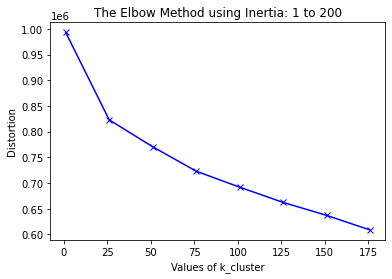

In [ ]:
plt.plot(k_cluster1, inertias, 'bx-') 
plt.xlabel('Values of k_cluster') 
plt.ylabel('Distortion') 
plt.title('The Elbow Method using Inertia: 1 to 200') 
plt.show() 

In [ ]:
k_cluster2 = range(200, 500, 25)

start_time2 = time.time()
inertias, map_inertia = koptim_elbow(svd_var_data, k_cluster2)
seconds_time_code2 = (time.time() - start_time2)

print("Time execution: ", round(seconds_time_code2, 2), "seconds.")

print(seconds_transform(seconds_time_code2))

Time execution:  527.1 seconds.
 0 h  8 min  47.1  s
None


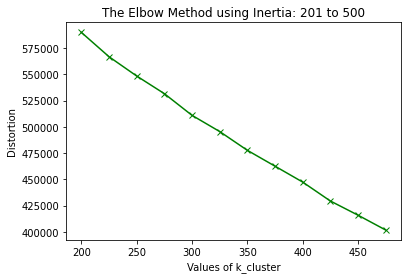

In [ ]:
plt.plot(k_cluster2, inertias, 'gx-') 
plt.xlabel('Values of k_cluster') 
plt.ylabel('Distortion') 
plt.title('The Elbow Method using Inertia: 201 to 500') 
plt.show()

Time execution:  4744.69 seconds.
 1 h  19 min  4.69  s
None


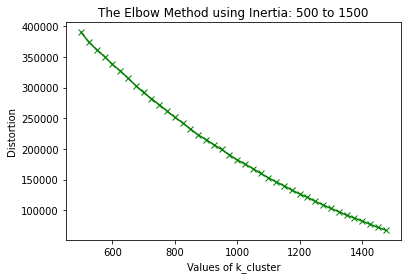

In [ ]:
k_cluster3 = range(500, 1500, 25)

start_time3 = time.time()
inertias, map_inertia = koptim_elbow(svd_var_data, k_cluster3)
seconds_time_code3 = (time.time() - start_time3)

print("Time execution: ", round(seconds_time_code3, 2), "seconds.")

print(seconds_transform(seconds_time_code3))

plt.plot(k_cluster3, inertias, 'gx-') 
plt.xlabel('Values of k_cluster') 
plt.ylabel('Distortion') 
plt.title('The Elbow Method using Inertia: 500 to 1500') 
plt.show() 

Time execution:  598.55 seconds.
 1 h  19 min  4.69  s
None


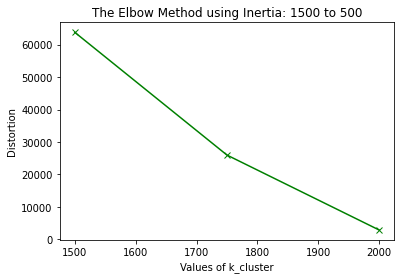

In [ ]:
k_cluster4 = range(1500, 2250, 250)

start_time4 = time.time()
inertias, map_inertia = koptim_elbow(svd_var_data, k_cluster4)
seconds_time_code4 = (time.time() - start_time4)

print("Time execution: ", round(seconds_time_code4, 2), "seconds.")

print(seconds_transform(seconds_time_code3))

plt.plot(k_cluster4, inertias, 'gx-') 
plt.xlabel('Values of k_cluster') 
plt.ylabel('Distortion') 
plt.title('The Elbow Method using Inertia: 1500 to 500') 
plt.show() 

O que foi possível testar está no range de 1 a 2225 (número máximo de documentos). Depois desse valor, o método Elbow não conseguiu mais calcular a inercia.

Após comparar os gráficos, um valor de dimensão que ficou razoável foi de 25.

# Questão 5

## (a) t-SNE vs UMAP

#### t-SNE

In [ ]:
from sklearn.manifold import TSNE

start_tsne = time.time()

pca_apply = PCA(n_components=25).fit_transform(x_pca_cv)

tsne = TSNE(random_state = 42).fit_transform(pca_apply)

time_tsne = (time.time() - start_tsne)
print("Time execution: ", round(time_tsne, 2), "seconds.")

/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:783: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:793: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  FutureWarning,


Time execution:  22.87 seconds.


In [ ]:
tsne_col = []
for i in range(0, 2225):
  tsne_col.append(tsne[i].sum())

tsne_colors = np.array(tsne_col)

Text(0, 0.5, 'tsne_2')

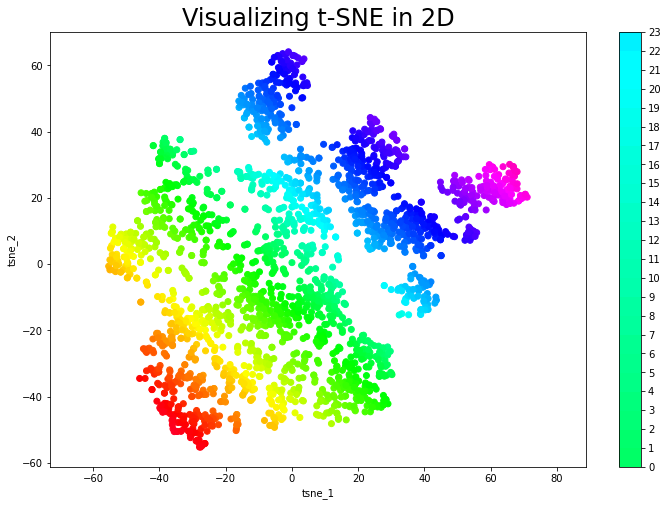

In [ ]:
# Plot tsne
fig = plt.figure(figsize=(12,8))
plt.scatter(tsne[:, 0], tsne[:, 1], c=tsne_colors, cmap='gist_rainbow')
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(24)).set_ticks(np.arange(24))
plt.title('Visualizing t-SNE in 2D', fontsize=24);
plt.xlabel('tsne_1')
plt.ylabel('tsne_2')

#### UMAP

In [ ]:
# Install UMAP: https://pypi.org/project/umap-learn/
# Solve UMAP: https://stackoverflow.com/questions/57242208/how-to-resolve-the-error-module-umap-has-no-attribute-umap-i-tried-installi

!pip uninstall umap
!pip install umap-learn

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
# UMAP
import umap.umap_ as umap

umap_ = umap.UMAP()

In [ ]:
umap_ = umap.UMAP(n_components=25).fit_transform(x_pca_cv)

time_tsne = (time.time() - start_tsne)
print("Time execution: ", round(time_tsne, 2), "seconds.")

Time execution:  111.52 seconds.


In [ ]:
print(umap_.shape)
umap_col = []
for i in range(0, 2225):
  umap_col.append(umap_[i].sum())

umap_colors = np.array(umap_col)

(2225, 25)


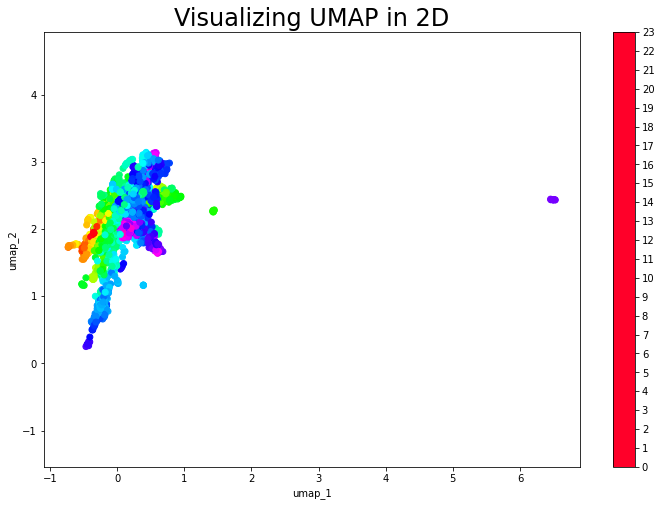

In [ ]:
# Visualising UMAP in 2d
fig = plt.figure(figsize=(12, 8))
plt.scatter(umap_[:, 0], umap_[:, 1], c=umap_colors, cmap='gist_rainbow')
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(24)).set_ticks(np.arange(24))
plt.xlabel('umap_1')
plt.ylabel('umap_2')
plt.title('Visualizing UMAP in 2D', fontsize=24);

## (c) perplexity t-SNE e n_neighbors do UMAP

### menor que default (30): perplexity t-SNE

/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:783: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:793: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  FutureWarning,


Time execution:  26.57 seconds.


Text(0, 0.5, 'tsne_2')

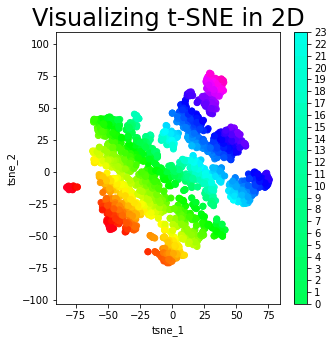

In [ ]:
start_tsne = time.time()
tsne = TSNE(random_state=42, perplexity=20).fit_transform(pca_apply)
time_tsne = (time.time() - start_tsne)
print("Time execution: ", round(time_tsne, 2), "seconds.")

tsne_col = []
for i in range(0, 2225):
  tsne_col.append(tsne[i].sum())

tsne_colors = np.array(tsne_col)

fig = plt.figure(figsize=(5, 5))
plt.scatter(tsne[:, 0], tsne[:, 1], c=tsne_colors, cmap='gist_rainbow')
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(24)).set_ticks(np.arange(24))
plt.title('Visualizing t-SNE in 2D', fontsize=24);
plt.xlabel('tsne_1')
plt.ylabel('tsne_2')

/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:783: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:793: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  FutureWarning,


Time execution:  13.2 seconds.


Text(0, 0.5, 'tsne_2')

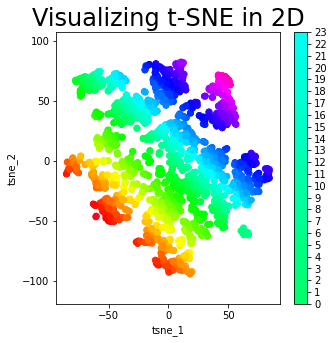

In [ ]:
start_tsne = time.time()
tsne = TSNE(random_state=42, perplexity=10).fit_transform(pca_apply)
time_tsne = (time.time() - start_tsne)
print("Time execution: ", round(time_tsne, 2), "seconds.")

tsne_col = []
for i in range(0, 2225):
  tsne_col.append(tsne[i].sum())

tsne_colors = np.array(tsne_col)

fig = plt.figure(figsize=(5, 5))
plt.scatter(tsne[:, 0], tsne[:, 1], c=tsne_colors, cmap='gist_rainbow')
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(24)).set_ticks(np.arange(24))
plt.title('Visualizing t-SNE in 2D', fontsize=24);
plt.xlabel('tsne_1')
plt.ylabel('tsne_2')

### maior que default: perplexity t-SNE

/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:783: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:793: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  FutureWarning,


Time execution:  24.69 seconds.


Text(0, 0.5, 'tsne_2')

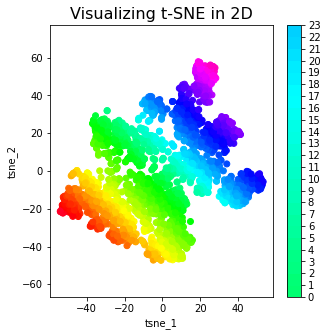

In [ ]:
start_tsne = time.time()
tsne = TSNE(random_state=42, perplexity=40).fit_transform(pca_apply)
time_tsne = (time.time() - start_tsne)
print("Time execution: ", round(time_tsne, 2), "seconds.")

tsne_col = []
for i in range(0, 2225):
  tsne_col.append(tsne[i].sum())

tsne_colors = np.array(tsne_col)

fig = plt.figure(figsize=(5, 5))
plt.scatter(tsne[:, 0], tsne[:, 1], c=tsne_colors, cmap='gist_rainbow')
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(24)).set_ticks(np.arange(24))
plt.title('Visualizing t-SNE in 2D', fontsize=16);
plt.xlabel('tsne_1')
plt.ylabel('tsne_2')

/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:783: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:793: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  FutureWarning,


Time execution:  30.54 seconds.


Text(0, 0.5, 'tsne_2')

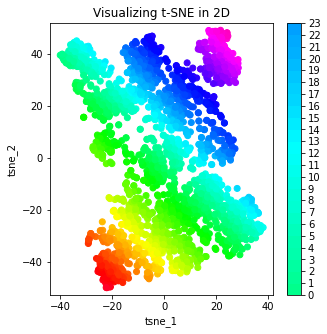

In [ ]:
start_tsne = time.time()
tsne = TSNE(random_state=42, perplexity=50).fit_transform(pca_apply)
time_tsne = (time.time() - start_tsne)
print("Time execution: ", round(time_tsne, 2), "seconds.")

tsne_col = []
for i in range(0, 2225):
  tsne_col.append(tsne[i].sum())

tsne_colors = np.array(tsne_col)

fig = plt.figure(figsize=(5, 5))
plt.scatter(tsne[:, 0], tsne[:, 1], c=tsne_colors, cmap='gist_rainbow')
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(24)).set_ticks(np.arange(24))
plt.title('Visualizing t-SNE in 2D', fontsize=12);
plt.xlabel('tsne_1')
plt.ylabel('tsne_2')

### menor que default: n_neighbors (15) UMAP

Time execution:  69.07 seconds.


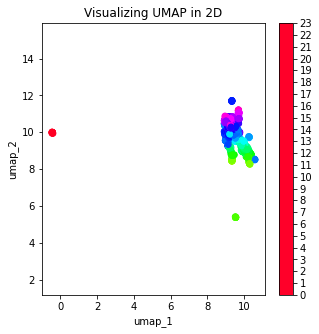

In [ ]:
# default: https://umap-learn.readthedocs.io/en/latest/parameters.html#n-neighbors
start_umap = time.time()
umap_ = umap.UMAP(n_components=25, n_neighbors=10).fit_transform(x_pca_cv)

time_umpa = (time.time() - start_umap)
print("Time execution: ", round(time_umpa, 2), "seconds.")

umap_col = []
for i in range(0, 2225):
  umap_col.append(umap_[i].sum())

umap_colors = np.array(umap_col)

# Visualising UMAP in 2d
fig = plt.figure(figsize=(5, 5))
plt.scatter(umap_[:, 0], umap_[:, 1], c=umap_colors, cmap='gist_rainbow')
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(24)).set_ticks(np.arange(24))
plt.xlabel('umap_1')
plt.ylabel('umap_2')
plt.title('Visualizing UMAP in 2D', fontsize=12);

Time execution:  56.09 seconds.


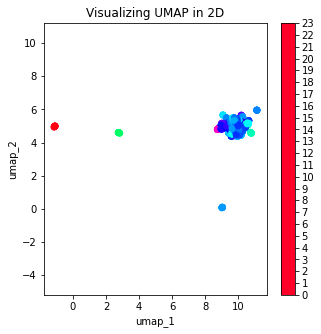

In [ ]:
# default: https://umap-learn.readthedocs.io/en/latest/parameters.html#n-neighbors
start_umap = time.time()
umap_ = umap.UMAP(n_components=25, n_neighbors=5).fit_transform(x_pca_cv)

time_umpa = (time.time() - start_umap)
print("Time execution: ", round(time_umpa, 2), "seconds.")

umap_col = []
for i in range(0, 2225):
  umap_col.append(umap_[i].sum())

umap_colors = np.array(umap_col)

# Visualising UMAP in 2d
fig = plt.figure(figsize=(5, 5))
plt.scatter(umap_[:, 0], umap_[:, 1], c=umap_colors, cmap='gist_rainbow')
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(24)).set_ticks(np.arange(24))
plt.xlabel('umap_1')
plt.ylabel('umap_2')
plt.title('Visualizing UMAP in 2D', fontsize=12);

### maior que default: UMAP

Time execution:  57.45 seconds.


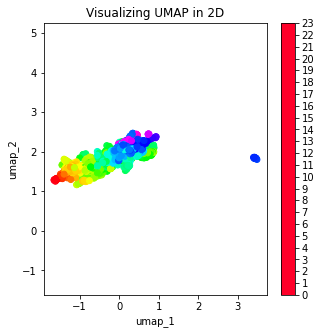

In [ ]:
# default: https://umap-learn.readthedocs.io/en/latest/parameters.html#n-neighbors
start_umap = time.time()
umap_ = umap.UMAP(n_components=25, n_neighbors=20).fit_transform(x_pca_cv)

time_umpa = (time.time() - start_umap)
print("Time execution: ", round(time_umpa, 2), "seconds.")

umap_col = []
for i in range(0, 2225):
  umap_col.append(umap_[i].sum())

umap_colors = np.array(umap_col)

# Visualising UMAP in 2d
fig = plt.figure(figsize=(5, 5))
plt.scatter(umap_[:, 0], umap_[:, 1], c=umap_colors, cmap='gist_rainbow')
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(24)).set_ticks(np.arange(24))
plt.xlabel('umap_1')
plt.ylabel('umap_2')
plt.title('Visualizing UMAP in 2D', fontsize=12);

Time execution:  62.68 seconds.


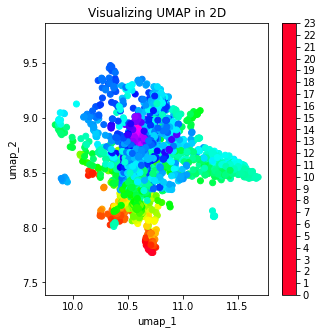

In [ ]:
# default: https://umap-learn.readthedocs.io/en/latest/parameters.html#n-neighbors
start_umap = time.time()
umap_ = umap.UMAP(n_components=25, n_neighbors=25).fit_transform(x_pca_cv)

time_umpa = (time.time() - start_umap)
print("Time execution: ", round(time_umpa, 2), "seconds.")

umap_col = []
for i in range(0, 2225):
  umap_col.append(umap_[i].sum())

umap_colors = np.array(umap_col)

# Visualising UMAP in 2d
fig = plt.figure(figsize=(5, 5))
plt.scatter(umap_[:, 0], umap_[:, 1], c=umap_colors, cmap='gist_rainbow')
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(24)).set_ticks(np.arange(24))
plt.xlabel('umap_1')
plt.ylabel('umap_2')
plt.title('Visualizing UMAP in 2D', fontsize=12);

## (c) Comparar t-SNE e UMAP (visualização e tempo de execução)

1. Técnica: t-SNE

Tempo de execução

1.1. perplexity = 20: 26.7 s

1.2. perplexity = 10: 13.2 s

1.3. perplexity = 40: 24.69 s

1.4. perplexity = 50: 30.54 s

2. Técnica: UMAP

Tempo de execução

1.1. perplexity = 10: 69.07 s

1.2. perplexity = 5: 56.09 s

1.3. perplexity = 20: 57.45 s

1.4. perplexity = 25: 62.68 s



O t-SNE se mostrou mais rápido, bem como uma separação mais nítida em todos os casos.

O UMAP melhorou a separação quando o valor foi ajustado para ser superior ao default. Porém a coloração ainda não é bem definida, mas apenas a separação espacial dos pontos.